# Group 8 — ISIC skin-lesion classification

Coding component skeleton. Every requirement from the client document maps to one section below.
Target runtime: local conda dev environment (Anaconda + Jupyter, Python 3.12, TensorFlow 2.21),
single TensorFlow / Keras stack.
Fill in the TODO blocks in order; each section must stay runnable from top to bottom.

**Datasets (both are used)**
- ISIC 2018 Task 3 (HAM10000, 7 classes) — train / validation / internal test, lesion-disjoint split
- ISIC 2019 (8 classes) — external validation, SCC excluded, hash-deduped against 2018

The third dataset listed in the client document (SIIM-ISIC 2020) is not used: its archive is over 100 GB.
This deviation is recorded in `AGENTS.md` and must be stated in the report.

**Fixed label space (7 classes)**: MEL, NV, BCC, AKIEC, BKL, DF, VASC


## Requirement map

| Section | Requirement | Main artifact |
|---|---|---|
| 0 | setup | paths, output folders, dataset file counts |
| 1 | 2.1 | library version table |
| 2 | 2.2 | gradient tape demonstration |
| 3 | 2.3 | training vs evaluation memory |
| data | foundation | `isic2018` / `isic2019` tables |
| 5 | 2.4 | preprocessing and label encoding |
| 6 | 2.5–2.6 | augmentation figure |
| 7 | 2.7–2.9 | `model.summary()`, feature maps |
| 8 | 1.1 | gradient-magnitude figure, VGG vs ResNet |
| 9 | 2.10–2.13 | training history and learning curves |
| 10 | 2.14–2.17 | confusion matrix, top-3 confident errors |
| 11 | 2.18–2.20 | external results, unseen image, calibration |
| 12 | submission | saved artifacts and results archive |

Coverage checklist: 1.1 · 2.1 · 2.2 · 2.3 · 2.4 · 2.5 · 2.6 · 2.7 · 2.8 · 2.9 · 2.10 · 2.11 ·
2.12 · 2.13 · 2.14 · 2.15 · 2.16 · 2.17 · 2.18 · 2.19 · 2.20


## Run plan

- **Once, before running anything**: download the two Kaggle datasets and unpack them into `data/`
  (the exact folder names are listed in section 0).
- **Session 1**: sections 0 → data layer; the printed counts must be larger than zero.
- **Session 2**: sections 2.1 → 2.9.
- **Session 3**: sections 2.10 → 2.13 (training, checkpoint each epoch).
- **Session 4**: sections 2.14 → 2.20 (evaluation and figures).


## 0. Setup and runtime

Download the two datasets from Kaggle **once** and unpack them into this project like this:

```
data/
  ISIC 2018/   HAM10000_metadata.csv + *.jpg   (HAM10000, 7 classes, 10,015 images)
  ISIC 2019/   ISIC_2019_Training_GroundTruth.csv + *.jpg
```

`data/` and `outputs/` are git-ignored, so the images never enter the repository.
The last line of the cell prints how many JPEGs are visible per dataset; a wrong folder name shows up
immediately as `0 jpg`.

Produces: fixed paths, output folders, seeds, dataset file counts.


In [1]:
# Section 0 - paths and seeds. The two datasets are downloaded once from Kaggle and unpacked here:
#   data/ISIC 2018/  data/ISIC 2019/
import os, random, hashlib
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # keep TensorFlow C++ logs out of the notebook output
from pathlib import Path
import numpy as np
import pandas as pd

def project_root(start: Path) -> Path:
    """Return the project root whether the kernel starts in the root or in code/ (local Jupyter)."""
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() or (candidate / "AGENTS.md").is_file():
            return candidate
    raise RuntimeError("open this notebook inside the project folder (data/ not found)")

ROOT = project_root(Path.cwd())
os.chdir(ROOT)                # keep every relative path below stable and portable
DATA_ROOT = Path("data")      # project folder; keep the same two subfolders
OUT_DIR = Path("outputs")     # figures and tables produced by later sections
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "tables").mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]  # fixed 7-class label space
IMG_SIZE = 224
BATCH_SIZE = 16

SEED = 8
random.seed(SEED)
np.random.seed(SEED)

assert DATA_ROOT.is_dir(), "create data/ with the two dataset folders first"
# First sanity check: every line must show a number larger than 0.
for name in ("ISIC 2018", "ISIC 2019"):
    print(f"{name:10s} {len(list((DATA_ROOT / name).rglob('*.jpg'))):6d} jpg")


ISIC 2018   10015 jpg
ISIC 2019   25331 jpg


## 2.1 Libraries

Required: list every library used and its version. Produces: printed version table saved to `env.json`.

In [2]:
# 2.1 - Record every library used and its version (saved to outputs/tables/env.json).
import warnings
warnings.filterwarnings("ignore")
import json, math, platform, time
import tensorflow as tf
import keras
import sklearn
import sklearn.metrics
from sklearn.utils.class_weight import compute_class_weight
import PIL
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

# TF 2.21 / CPU: the MLIR meta optimizer prints spurious "operand does not dominate" errors for
# GradientTape graphs. Disabling it keeps the output clean and leaves training speed unchanged.
tf.config.optimizer.set_experimental_options({"disable_meta_optimizer": True})

ENV = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": PIL.__version__,
}
env_df = pd.DataFrame({"library": list(ENV), "version": list(ENV.values())})
print(env_df.to_string(index=False))
(OUT_DIR / "tables" / "env.json").write_text(json.dumps(ENV, indent=2))

# One seed for python, numpy and tensorflow; section 0 already fixed SEED.
tf.keras.utils.set_random_seed(SEED)
print("\nrandom seed:", SEED)


     library version
      python 3.12.12
  tensorflow  2.21.0
       keras  3.15.0
       numpy   2.5.1
      pandas   3.0.5
scikit-learn   1.9.1
  matplotlib  3.11.2
      pillow  12.3.0

random seed: 8


## 2.2 Forward pass and automatic differentiation

Required: explain how the framework tracks the forward pass and recovers gradients. Produces: per-layer gradient norms for one real batch.

**What the tape records.** While the `GradientTape` context is open, TensorFlow stores every operation whose inputs include a trainable variable together with the tensors needed to differentiate it. Closing the context freezes that recording; `tape.gradient()` then replays it in reverse (chain rule) and returns one gradient tensor per trainable variable. The tape keeps references to intermediate activations until it is consumed, which is why training needs more memory than inference.


In [3]:
# 2.2 - A real image batch, one real forward pass, and the gradients the tape recovers.
def load_raw_batch(folder, n=8):
    """Read JPEGs straight from disk: this is the autodiff demo, full preprocessing comes in 2.4."""
    paths = sorted(p for p in (DATA_ROOT / folder).rglob("*.jpg"))[:n]
    batch = [np.asarray(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
             for p in paths]
    return tf.convert_to_tensor(np.stack(batch)), paths

demo_x, demo_paths = load_raw_batch("ISIC 2018")
demo_y = tf.one_hot([0, 1, 2, 3, 4, 5, 6, 0], depth=len(CLASS_NAMES))

demo_model = tf.keras.Sequential([
    tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(16, 3, strides=2, activation="relu"),
    tf.keras.layers.Conv2D(32, 3, strides=2, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(len(CLASS_NAMES)),
], name="tape_demo")
demo_loss = tf.keras.losses.CategoricalCrossentropy(from_logits=True)

# Every operation that depends on a trainable variable is recorded while the context is open.
with tf.GradientTape() as tape:
    logits = demo_model(demo_x, training=True)
    loss = demo_loss(demo_y, logits)

# gradient() replays the recorded graph backwards (chain rule) and returns one tensor per variable.
grads = tape.gradient(loss, demo_model.trainable_variables)
print("demo batch:", tuple(demo_x.shape), "| loss:", round(float(loss), 4))

grad_rows = [{"layer": var.name, "shape": tuple(var.shape),
              "grad_norm": float(tf.norm(g)) if g is not None else 0.0}
             for var, g in zip(demo_model.trainable_variables, grads)]
grad_df = pd.DataFrame(grad_rows)
print(grad_df.to_string(index=False))
grad_df.to_csv(OUT_DIR / "tables" / "gradient_norms_2_2.csv", index=False)


demo batch: (8, 224, 224, 3) | loss: 1.9424
 layer          shape  grad_norm
kernel  (3, 3, 3, 16)   0.183159
  bias          (16,)   0.049229
kernel (3, 3, 16, 32)   0.278156
  bias          (32,)   0.087673
kernel        (32, 7)   0.097303
  bias           (7,)   0.123401


## 2.3 Training and evaluation memory

Required: explain the memory difference between training and evaluation mode. Produces: behaviour evidence and written comparison.

**Why training costs more memory.** In training mode the framework keeps every intermediate activation needed by the backward pass, BatchNormalization uses the statistics of the current batch, and dropout samples a new mask on every call. In evaluation mode no backward pass follows, so activations can be released as soon as they are produced, BatchNormalization reuses the moving statistics learned during training, and dropout is switched off - the output is deterministic and no tape is needed. The printed comparison shows the two regimes: training-mode calls disagree with each other, evaluation-mode calls are identical.


In [4]:
# 2.3 - Training mode versus evaluation mode: behaviour evidence and cost evidence.
demo_model3 = tf.keras.Sequential([
    tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(16, 3, strides=2, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(len(CLASS_NAMES)),
], name="mode_demo")

train_out_a = demo_model3(demo_x, training=True)
train_out_b = demo_model3(demo_x, training=True)
eval_out_a = demo_model3(demo_x, training=False)
eval_out_b = demo_model3(demo_x, training=False)
print("training=True  -> max |call1 - call2|:", round(float(tf.reduce_max(tf.abs(train_out_a - train_out_b))), 6))
print("training=False -> max |call1 - call2|:", round(float(tf.reduce_max(tf.abs(eval_out_a - eval_out_b))), 6))

@tf.function
def forward_eval(x):
    return demo_model3(x, training=False)

@tf.function
def forward_train_with_tape(x):
    with tf.GradientTape() as tape:
        y = demo_model3(x, training=True)
        loss = tf.reduce_mean(y)
    return tape.gradient(loss, demo_model3.trainable_variables)

def time_forward(fn, repeats=3):
    fn(demo_x)                      # first call traces the tf.function
    start = time.perf_counter()
    for _ in range(repeats):
        fn(demo_x)
    return (time.perf_counter() - start) / repeats

t_eval = time_forward(forward_eval)
t_train = time_forward(forward_train_with_tape)
print(f"eval forward: {t_eval * 1000:.1f} ms | training forward + backward: {t_train * 1000:.1f} ms")
print(f"one training step costs {t_train / t_eval:.1f}x the evaluation pass on this batch")


training=True  -> max |call1 - call2|: 0.014982
training=False -> max |call1 - call2|: 0.0
eval forward: 1.5 ms | training forward + backward: 7.2 ms
one training step costs 4.9x the evaluation pass on this batch


## Data layer: load the two datasets from the project folder

No download code is needed: the folders above are read directly. Each dataset becomes one small table
with the columns the later sections need (`image`, `path`, `label` / `target`, `split`, `md5`).

Rules applied here:
- fixed 7-class label space; HAM10000 lowercase codes are mapped to class names;
- lesion-level split for ISIC 2018, so all images of one lesion stay in one split;
- SCC dropped from ISIC 2019 (the model has no SCC slot);
- duplicate images removed from ISIC 2019 by file md5 (it largely repeats ISIC 2018).

Produces: the `isic2018` and `isic2019` tables, plus `outputs/tables/isic2018_split.csv`.


In [5]:
# 2.4 - ISIC 2018 (HAM10000): build image path + 7-class label + lesion id.
# HAM10000 stores lowercase codes such as "mel"; map them to the fixed class names.
DX_TO_CLASS = {"mel": "MEL", "nv": "NV", "bcc": "BCC", "akiec": "AKIEC",
               "bkl": "BKL", "df": "DF", "vasc": "VASC"}

base = DATA_ROOT / "ISIC 2018"
meta_path = next(base.rglob("HAM10000_metadata.csv"), None)
assert meta_path is not None, "data/ISIC 2018 must contain HAM10000_metadata.csv"
meta = pd.read_csv(meta_path)
jpgs = {p.stem: p for p in base.rglob("*.jpg")}     # image name -> full path

isic2018 = meta[["image_id", "lesion_id", "dx"]].rename(columns={"image_id": "image"})
isic2018["label"] = isic2018["dx"].map(DX_TO_CLASS)
isic2018["path"] = isic2018["image"].map(lambda name: str(jpgs[name]))
print(isic2018["label"].value_counts().to_string())


label
NV       6705
MEL      1113
BKL      1099
BCC       514
AKIEC     327
VASC      142
DF        115


In [6]:
# Lesion-level split: all images of one lesion land in the same split (no leakage between splits).
lesions = sorted(isic2018["lesion_id"].unique())
np.random.RandomState(SEED).shuffle(lesions)
val_lesions = set(lesions[int(len(lesions) * 0.70):int(len(lesions) * 0.85)])
test_lesions = set(lesions[int(len(lesions) * 0.85):])

def split_of(lesion_id):
    if lesion_id in val_lesions:
        return "validation"
    if lesion_id in test_lesions:
        return "test"
    return "train"

isic2018["split"] = isic2018["lesion_id"].map(split_of)
isic2018.to_csv(OUT_DIR / "tables" / "isic2018_split.csv", index=False)
print(isic2018["split"].value_counts().to_string())


split
train         7029
test          1500
validation    1486


In [7]:
# 2.4 - ISIC 2019 is the external validation set. It has 8 classes; SCC has no slot in our 7 classes.
# The ground-truth CSV stores AKIEC as "AK", so the column names are mapped to the fixed class names.
ISIC2019_CLASSES = {"MEL": "MEL", "NV": "NV", "BCC": "BCC", "AK": "AKIEC",
                    "BKL": "BKL", "DF": "DF", "VASC": "VASC", "SCC": "SCC"}

base = DATA_ROOT / "ISIC 2019"
jpgs = {p.stem: p for p in base.rglob("*.jpg")}
truth_path = next(base.rglob("ISIC_2019_Training_GroundTruth.csv"), None)
assert truth_path is not None, "data/ISIC 2019 must contain ISIC_2019_Training_GroundTruth.csv"
truth = pd.read_csv(truth_path)
truth["label"] = truth[list(ISIC2019_CLASSES)].idxmax(axis=1).map(ISIC2019_CLASSES)
scc_count = int((truth["label"] == "SCC").sum())
isic2019 = truth[truth["label"] != "SCC"][["image", "label"]].copy()
isic2019["path"] = isic2019["image"].map(lambda name: str(jpgs[name]))
isic2019["split"] = "external_val"
print("isic2019:", len(isic2019), "| SCC dropped:", scc_count)


isic2019: 24703 | SCC dropped: 628


In [8]:
# ISIC 2019 largely repeats ISIC 2018 images, so remove them: the external set must be unseen.
def md5(path):
    with open(path, "rb") as handle:
        return hashlib.md5(handle.read()).hexdigest()

isic2018["md5"] = [md5(p) for p in isic2018["path"]]
isic2019["md5"] = [md5(p) for p in isic2019["path"]]
duplicates = isic2019["md5"].isin(isic2018["md5"])
isic2019 = isic2019[~duplicates].reset_index(drop=True)
print("duplicate images removed from isic2019:", int(duplicates.sum()))
print("rows -> isic2018:", len(isic2018), "| isic2019:", len(isic2019))


duplicate images removed from isic2019: 9818
rows -> isic2018: 10015 | isic2019: 14885


## 2.4 Preprocessing and label encoding

Required: preprocessing, augmentation and label encoding. Produces: fixed class order, uint8 cache, `tf.data` pipeline, one-hot labels.

**Preprocessing here.** Each JPEG is decoded and resized to `IMG_SIZE` once; the `uint8` result is cached under `outputs/cache/` so later sessions skip JPEG decoding. Labels use the fixed `CLASS_NAMES` order and are one-hot encoded; the three `tf.data` pipelines shuffle (train only), batch and prefetch.


In [9]:
# 2.4 - Preprocessing and label encoding: decode/resize once, cache uint8 arrays, build tf.data pipelines.
CACHE_DIR = OUT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}

def decode_resize(path):
    """JPEG bytes -> uint8 RGB tensor of shape (IMG_SIZE, IMG_SIZE, 3)."""
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method="bilinear")
    return tf.cast(image, tf.uint8)

def load_split(split_df):
    """Decode one split with a parallel tf.data map; return uint8 images and integer labels."""
    paths = tf.constant(split_df["path"].tolist())
    labels = np.array([CLASS_TO_INDEX[label] for label in split_df["label"]], dtype=np.int32)
    images = tf.data.Dataset.from_tensor_slices(paths).map(decode_resize, num_parallel_calls=AUTOTUNE)
    return np.stack(list(images.as_numpy_iterator())), labels

SPLITS = {}
for name in ("train", "validation", "test"):
    split_df = isic2018[isic2018["split"] == name]
    x_path, y_path = CACHE_DIR / f"{name}_x.npy", CACHE_DIR / f"{name}_y.npy"
    if x_path.is_file() and y_path.is_file():
        x, y, source = np.load(x_path), np.load(y_path), "cache"
    else:
        start = time.perf_counter()
        x, y = load_split(split_df)
        np.save(x_path, x)
        np.save(y_path, y)
        source = f"decoded in {time.perf_counter() - start:.1f}s"
    SPLITS[name] = (x, y)
    print(f"{name:10s} {x.shape[0]:5d} images | {x.shape[1]}x{x.shape[2]}x{x.shape[3]} | {x.dtype} | {source}")

def prepare_sample(image, label):
    """Normalise to [0, 1] and one-hot encode the fixed 7-class label."""
    return tf.cast(image, tf.float32) / 255.0, tf.one_hot(label, len(CLASS_NAMES))

x_train, y_train = SPLITS["train"]
x_val, y_val = SPLITS["validation"]
x_test, y_test = SPLITS["test"]

# train_base stays unbatched so 2.5 can apply training-only augmentation before batching.
train_base = tf.data.Dataset.from_tensor_slices((x_train, y_train)).map(prepare_sample, num_parallel_calls=AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).map(prepare_sample, num_parallel_calls=AUTOTUNE).batch(32).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).map(prepare_sample, num_parallel_calls=AUTOTUNE).batch(32).prefetch(AUTOTUNE)

train_labels = y_train.copy()          # integer labels kept for class weights in 2.10
class_counts = pd.Series(train_labels).map(CLASS_NAMES.__getitem__).value_counts().reindex(CLASS_NAMES)
print("\ntraining images per class:\n" + class_counts.to_string())
print(f"\ntrain batches per epoch: {math.ceil(len(train_labels) / BATCH_SIZE)}")
for images, labels in val_ds.take(1):
    print("validation batch:", tuple(images.shape), "| labels:", tuple(labels.shape),
          "| one-hot row:", labels[0].numpy().astype(int))

# The datasets now hold the image tensors; release the numpy copies.
del SPLITS, x_train, y_train, x_val, y_val, x_test, y_test


train       7029 images | 224x224x3 | uint8 | cache
validation  1486 images | 224x224x3 | uint8 | cache
test        1500 images | 224x224x3 | uint8 | cache



training images per class:
MEL       811
NV       4681
BCC       366
AKIEC     220
BKL       773
DF         78
VASC      100

train batches per epoch: 440
validation batch: (32, 224, 224, 3) | labels: (32, 7) | one-hot row: [0 0 0 0 1 0 0]


## 2.5–2.6 Augmentation

Required: show two random augmentations of one sample side by side; explain variance without label change. Produces: augmentation figure.

**Augmentation.** Horizontal/vertical flips, small rotations, zoom, translation, contrast and brightness changes are applied only to the training split. They change the pixel statistics of an image - so the model sees extra variance - but never change its label. Validation and test images are never augmented.


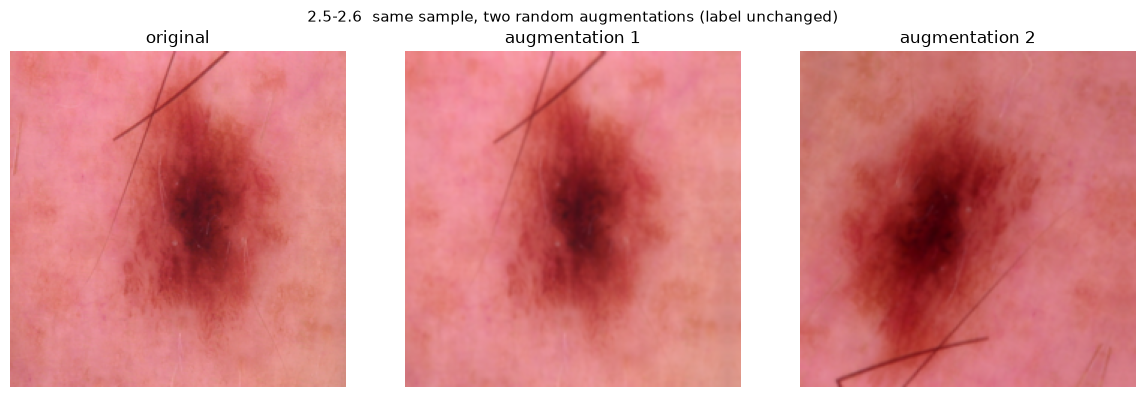

In [10]:
# 2.5 - Training-only augmentation, implemented with Keras preprocessing layers.
AUGMENT = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, fill_mode="reflect", seed=SEED),
    tf.keras.layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="reflect", seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
    tf.keras.layers.RandomBrightness(0.10, value_range=(0.0, 1.0), seed=SEED),
], name="augment")

def augment(image, label):
    image = AUGMENT(image, training=True)
    return tf.clip_by_value(image, 0.0, 1.0), label

train_ds = (train_base
            .shuffle(1000, seed=SEED)
            .map(augment, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

# 2.6 - One sample and two independent random augmentations of the same sample.
sample_path = sorted((DATA_ROOT / "ISIC 2018").rglob("*.jpg"))[0]
sample = tf.convert_to_tensor(
    np.asarray(Image.open(sample_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0)
panels = [("original", sample),
          ("augmentation 1", AUGMENT(sample, training=True)),
          ("augmentation 2", AUGMENT(sample, training=True))]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, panel) in zip(axes, panels):
    ax.imshow(np.clip(panel.numpy(), 0.0, 1.0))
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("2.5-2.6  same sample, two random augmentations (label unchanged)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()


## 2.7–2.9 Model, summary and feature maps

Required: build the model, print summary, extract feature maps, explain shapes and backpropagation. Produces: summary file, parameter counts, feature-map grid.

**ImageNet preprocessing.** The pretrained weights expect the caffe-style input (RGB -> BGR, per-channel mean subtraction), so a `Lambda` layer converts the [0, 1] pipeline tensors to that format before the frozen backbone.

**Reading the model.** ResNet-50 first shrinks the spatial size (224 -> 7) while growing the channel depth (3 -> 2048), so the GAP layer sees one 2048-d vector per image; the dense head then maps it to 7 probabilities. Backpropagation starts from the softmax/cross-entropy gradient and applies the chain rule layer by layer, updating the head first and, in stage 2, the residual blocks. Residual shortcuts let the gradient flow around blocks instead of only through them.


Model: "resnet50_isic2018"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagenet_preprocess (Lambda)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)    

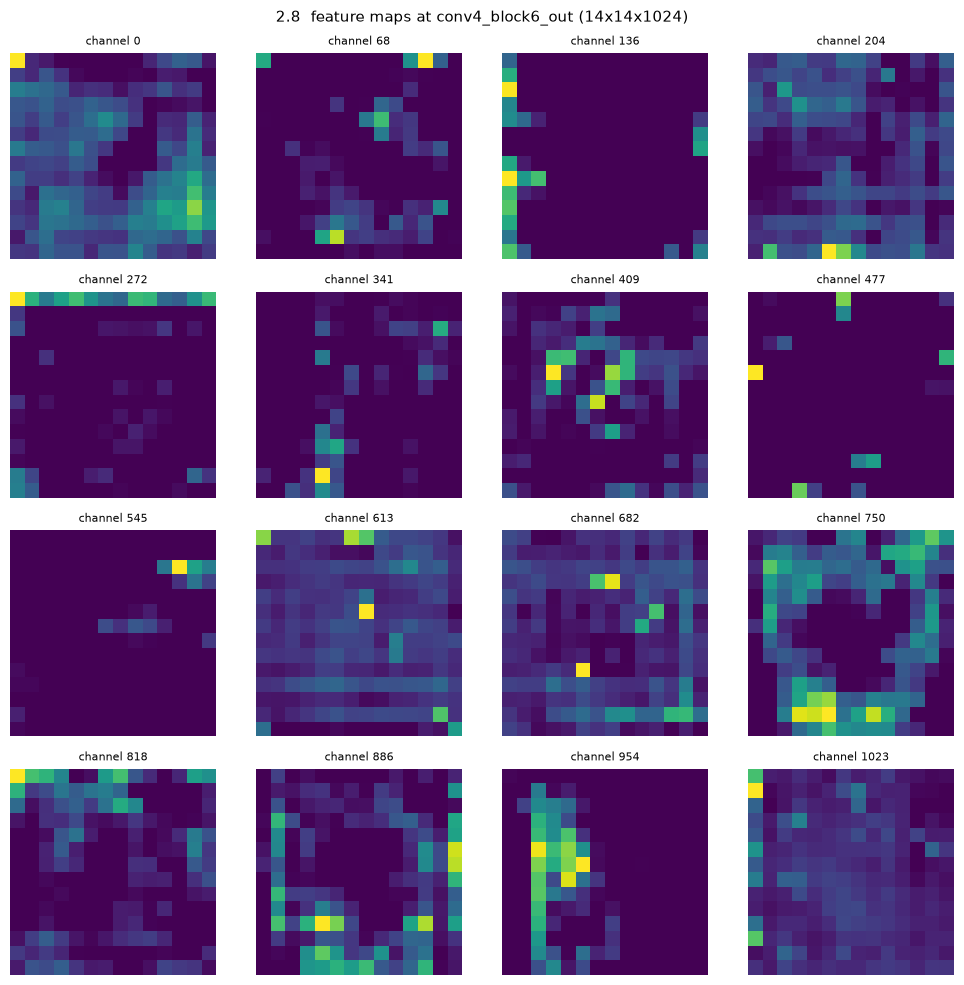

Input 224x224x3 -> conv4_block6_out 14x14x1024: spatial size / 16, channel depth x341


In [11]:
# 2.7 - ResNet-50 backbone (ImageNet weights) + GAP + dropout + softmax head.
base_model = tf.keras.applications.ResNet50(include_top=False, weights="imagenet",
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False      # stage 1 trains the head only; 2.10 unfreezes the last block
model = tf.keras.Sequential([
    tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Lambda(lambda x: tf.keras.applications.resnet50.preprocess_input(x * 255.0),
                           name="imagenet_preprocess"),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax", name="predictions"),
], name="resnet50_isic2018")

summary_lines = []
model.summary(print_fn=summary_lines.append)
summary_text = "\n".join(summary_lines)
(OUT_DIR / "tables" / "model_summary.txt").write_text(summary_text + "\n")
print(summary_text)
trainable_now = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"\ntotal parameters: {model.count_params():,} | trainable in stage 1: {trainable_now:,}")

# 2.8 - Feature maps from one hidden layer for one test image.
for images, labels in test_ds.take(1):
    test_image, test_label = images[0], int(tf.argmax(labels[0]))
feature_layer = base_model.get_layer("conv4_block6_out")
feature_extractor = tf.keras.Model(inputs=base_model.input, outputs=feature_layer.output)
preprocessed = tf.keras.applications.resnet50.preprocess_input(
    np.expand_dims(test_image.numpy(), axis=0) * 255.0)      # same preprocessing as the model
feature_maps = feature_extractor(tf.convert_to_tensor(preprocessed), training=False)[0].numpy()
print(f"feature map shape: {feature_maps.shape} | test image class: {CLASS_NAMES[test_label]}")

channels = np.linspace(0, feature_maps.shape[-1] - 1, 16).astype(int)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, channel in zip(axes.ravel(), channels):
    ax.imshow(feature_maps[:, :, channel], cmap="viridis")
    ax.set_title(f"channel {channel}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"2.8  feature maps at conv4_block6_out ({feature_maps.shape[0]}x{feature_maps.shape[1]}x{feature_maps.shape[2]})",
             fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "feature_maps.png", dpi=150, bbox_inches="tight")
plt.show()

# 2.9 - Why the spatial size shrinks while the channel depth grows (report section 2.9).
print("Input %dx%dx3 -> conv4_block6_out %dx%dx%d: spatial size / %d, channel depth x%.0f"
      % (IMG_SIZE, IMG_SIZE, feature_maps.shape[0], feature_maps.shape[1], feature_maps.shape[2],
         IMG_SIZE // feature_maps.shape[0], feature_maps.shape[2] / 3))


## Part 1.1 support: gradient magnitude per layer, VGG vs ResNet

Required by 1.1: a graph of gradient magnitudes per layer for VGG vs ResNet. Produces: the Part 1 figure and its data table.

**Vanishing gradients in a stack.** The chain rule multiplies the Jacobian of every layer, so repeated factors below 1 shrink the gradient as it travels backwards; in a plain VGG stack the earliest convolutions receive much smaller gradients than the last ones. ReLU keeps the derivative at 0 or 1 and therefore does not attenuate active paths the way saturating sigmoid/tanh units do, but it also switches off paths whose pre-activation is negative. Residual shortcuts add an identity term to the Jacobian, so part of the gradient reaches the early layers without being multiplied by every weight matrix. The figure records the L2 norm of the loss gradient for every trainable weight tensor of VGG16 and ResNet-50 on the same real batch.


                min     median        max
model                                    
ResNet-50  3.470826   6.133307  16.407007
VGG16      9.899051  18.060762  35.211994


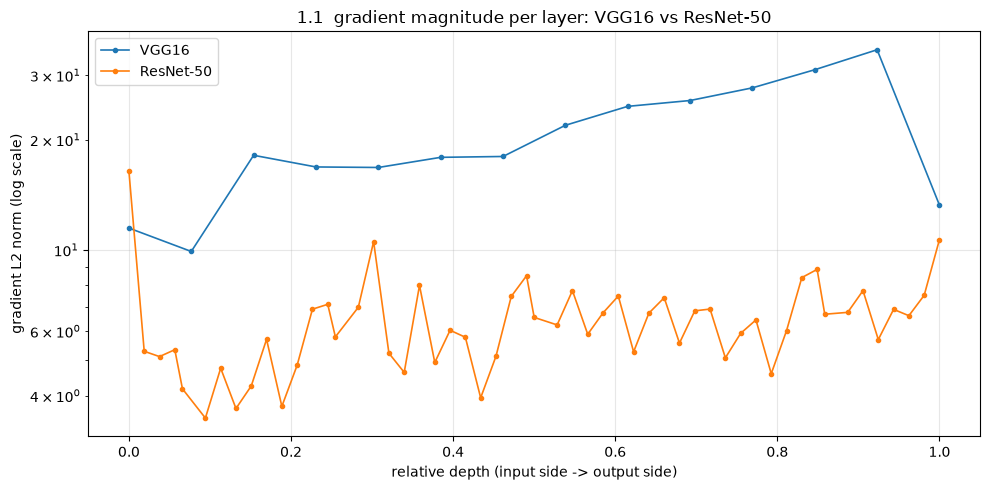

In [12]:
# 1.1 - Gradient magnitude per trainable layer for VGG16 versus ResNet-50, same real batch.
def imagenet_model(builder, preprocess_input, name):
    """Backbone with the ImageNet preprocessing it expects, plus a fresh 7-class head."""
    return tf.keras.Sequential([
        tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3)),
        tf.keras.layers.Lambda(lambda x: preprocess_input(x * 255.0)),
        builder(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(len(CLASS_NAMES)),
    ], name=name)

def per_layer_gradient_table(net, batch):
    """L2 norm of d(loss)/d(weight) for every conv/dense kernel of one forward+backward pass."""
    labels = tf.one_hot([index % len(CLASS_NAMES) for index in range(batch.shape[0])], len(CLASS_NAMES))
    with tf.GradientTape() as tape:
        loss = tf.keras.losses.CategoricalCrossentropy()(labels, net(batch, training=True))
    gradients = tape.gradient(loss, net.trainable_variables)
    rows = []
    for depth, (variable, gradient) in enumerate(zip(net.trainable_variables, gradients)):
        if gradient is None or len(variable.shape) < 2:      # kernels only, skip biases
            continue
        rows.append({"depth_index": depth, "layer": variable.name,
                     "grad_norm": float(tf.norm(gradient))})
    return pd.DataFrame(rows)

vgg_net = imagenet_model(tf.keras.applications.VGG16, tf.keras.applications.vgg16.preprocess_input, "vgg16_gradients")
resnet_net = imagenet_model(tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input, "resnet50_gradients")
vgg_table = per_layer_gradient_table(vgg_net, demo_x).assign(model="VGG16")
resnet_table = per_layer_gradient_table(resnet_net, demo_x).assign(model="ResNet-50")
gradient_table = pd.concat([vgg_table, resnet_table], ignore_index=True)
gradient_table["relative_depth"] = gradient_table.groupby("model")["depth_index"].transform(
    lambda column: column / max(column.max(), 1))
gradient_table.to_csv(OUT_DIR / "tables" / "gradient_magnitudes_1_1.csv", index=False)
print(gradient_table.groupby("model")["grad_norm"].agg(["min", "median", "max"]).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
for model_name, color in (("VGG16", "tab:blue"), ("ResNet-50", "tab:orange")):
    part = gradient_table[gradient_table["model"] == model_name].sort_values("relative_depth")
    ax.plot(part["relative_depth"], part["grad_norm"].clip(lower=1e-12),
            color=color, marker="o", markersize=3, linewidth=1.2, label=model_name)
ax.set_yscale("log")
ax.set_xlabel("relative depth (input side -> output side)")
ax.set_ylabel("gradient L2 norm (log scale)")
ax.set_title("1.1  gradient magnitude per layer: VGG16 vs ResNet-50")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "gradient_magnitudes_vgg_vs_resnet.png", dpi=150, bbox_inches="tight")
plt.show()

del vgg_net, resnet_net      # the gradient tables and figure are enough; free the two extra models


## 2.10–2.13 Training and learning curves

Required: adaptive optimizer, fixed epochs, loss curves with learning rate or gradient norm, overfitting analysis. Produces: training history and curves.

**Training plan.** The head is trained first with the frozen ImageNet backbone (AdamW, learning rate 5e-4). The last two residual stages are then unfrozen for five epochs at a much smaller learning rate (1e-5), so the pretrained filters adapt without being destroyed. Class weights compensate the imbalance (NV alone is about two thirds of the training split): balanced weights are square-rooted and capped at 5, because the raw weights would up-weight the tiny DF / VASC classes by more than 10x and sacrifice melanoma recall. Every epoch saves weights and appends one row to `outputs/tables/train_history.csv`, so an interrupted run resumes after the last completed epoch instead of starting over. `AdamW` is the adaptive optimizer: it keeps first and second moment estimates per parameter and decouples weight decay from the gradient step.


class  weight
  MEL   1.113
   NV   0.463
  BCC   1.656
AKIEC   2.136
  BKL   1.140
   DF   3.588
 VASC   3.169

epochs already in history: 9
training already complete: reusing outputs/tables/train_history.csv
stage  epoch      lr  train_loss  train_loss_weighted  train_acc  val_loss  val_acc  grad_norm    seconds
    A      1 0.00050    0.729199             0.956285   0.766193  1.910315 0.679677  10.344149 190.405399
    A      2 0.00050    0.628776             0.745433   0.809091  1.740808 0.672948   9.453202 187.512636
    A      3 0.00050    0.560333             0.671161   0.816193  1.949870 0.683042   9.227399 189.437970
    A      4 0.00050    0.529651             0.637357   0.836364  1.628913 0.689771   8.757175 189.300548
    B      1 0.00001    0.997667             1.181621   0.699688  1.424989 0.705922  27.415498 397.949576
    B      2 0.00001    0.784223             0.867514   0.745597  1.280910 0.715343  22.403054 395.472567
    B      3 0.00001    0.632413             0.6

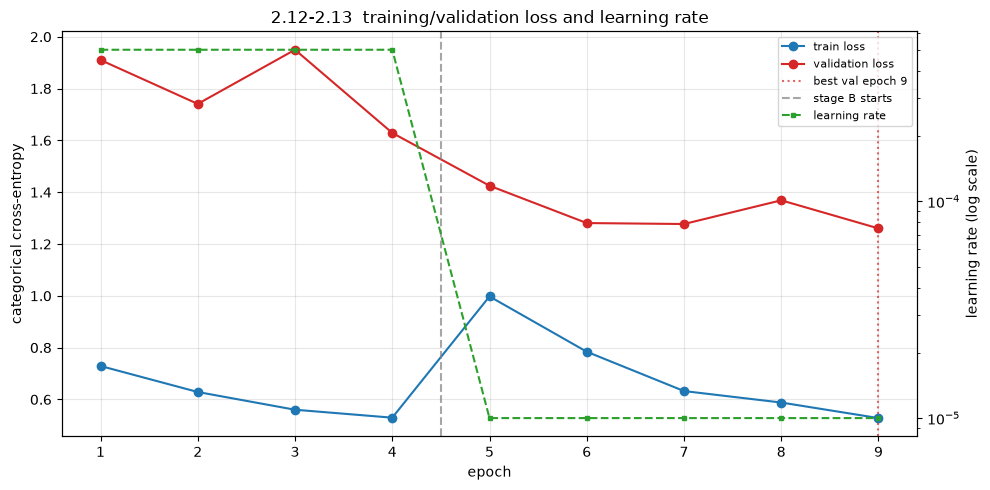

best validation loss 1.2602 (accuracy 0.726) at epoch 9
last epoch: train loss 0.5281 | val loss 1.2602 | gap +0.7321
total training time: 45.5 min


In [13]:
# 2.10 - Fixed two-stage training plan with AdamW, class weights and a checkpoint per epoch.
MODEL_DIR = OUT_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
LAST_WEIGHTS = MODEL_DIR / "last.weights.h5"
BEST_WEIGHTS = MODEL_DIR / "best.weights.h5"
HISTORY_PATH = OUT_DIR / "tables" / "train_history.csv"

STAGE_A_EPOCHS = 4          # frozen backbone: train the head only
STAGE_B_EPOCHS = 5          # unfreeze the last two residual stages and fine-tune gently
HEAD_LR = 5e-4
FINETUNE_LR = 1e-5
HISTORY_COLUMNS = ["stage", "epoch", "lr", "train_loss", "train_loss_weighted", "train_acc",
                   "val_loss", "val_acc", "grad_norm", "seconds"]
loss_fn = tf.keras.losses.CategoricalCrossentropy()                 # scalar mean, only for metrics
sample_loss_fn = tf.keras.losses.CategoricalCrossentropy(reduction="none")  # one loss per image

# 2.10 - class weights from the training split only.
class_weight_values = compute_class_weight(
    class_weight="balanced", classes=np.arange(len(CLASS_NAMES)), y=train_labels)
# Square-root damping: plain balanced weights would up-weight DF / VASC by 10-13x, which pushes the
# model towards those tiny classes and collapses melanoma recall. sqrt(weight), capped at 5, keeps the
# rare classes visible without letting them dominate the gradient.
class_weight_values = np.clip(np.sqrt(class_weight_values), None, 5.0)
CLASS_WEIGHTS = tf.constant(class_weight_values, dtype=tf.float32)
print(pd.DataFrame({"class": CLASS_NAMES, "weight": class_weight_values.round(3)}).to_string(index=False))

history = pd.read_csv(HISTORY_PATH) if HISTORY_PATH.is_file() else pd.DataFrame(columns=HISTORY_COLUMNS)
print("\nepochs already in history:", len(history))

def evaluate(model, dataset):
    """Unweighted loss and accuracy over a tf.data dataset."""
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in dataset:
        probabilities = model(images, training=False)
        total_loss += float(tf.reduce_sum(sample_loss_fn(labels, probabilities)))
        correct += int(tf.reduce_sum(tf.cast(tf.argmax(probabilities, 1) == tf.argmax(labels, 1), tf.int32)))
        seen += int(images.shape[0])
    return total_loss / seen, correct / seen

def make_train_step(optimizer):
    """One graph-mode step: class-weighted loss, gradient norm and accuracy."""
    @tf.function
    def train_step(images, labels):
        sample_weights = tf.reduce_sum(labels * CLASS_WEIGHTS, axis=-1)
        with tf.GradientTape() as tape:
            probabilities = model(images, training=True)
            per_image_loss = sample_loss_fn(labels, probabilities)
            weighted_loss = tf.reduce_sum(per_image_loss * sample_weights) / tf.reduce_sum(sample_weights)
        gradients = tape.gradient(weighted_loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        accuracy = tf.reduce_mean(tf.cast(tf.argmax(probabilities, 1) == tf.argmax(labels, 1), tf.float32))
        return weighted_loss, tf.reduce_mean(per_image_loss), tf.linalg.global_norm(gradients), accuracy
    return train_step

def run_stage(stage, optimizer, epochs):
    """Run one training stage, logging loss / learning rate / gradient norm and checkpointing."""
    global history
    trainable_now = sum(int(np.prod(weight.shape)) for weight in model.trainable_weights)
    print(f"\nstage {stage}: {epochs} epoch(s), lr={float(optimizer.learning_rate):.0e}, trainable weights={trainable_now:,}")
    train_step = make_train_step(optimizer)
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        losses, weighted_losses, accuracies, gradient_norms = [], [], [], []
        for images, labels in train_ds:
            weighted_loss, loss_value, gradient_norm, accuracy = train_step(images, labels)
            losses.append(float(loss_value))
            weighted_losses.append(float(weighted_loss))
            gradient_norms.append(float(gradient_norm))
            accuracies.append(float(accuracy))
        val_loss, val_accuracy = evaluate(model, val_ds)
        row = {"stage": stage, "epoch": epoch, "lr": float(optimizer.learning_rate),
               "train_loss": float(np.mean(losses)), "train_loss_weighted": float(np.mean(weighted_losses)),
               "train_acc": float(np.mean(accuracies)),
               "val_loss": val_loss, "val_acc": val_accuracy,
               "grad_norm": float(np.mean(gradient_norms)), "seconds": time.perf_counter() - start}
        history = pd.concat([history, pd.DataFrame([row])], ignore_index=True)
        history.to_csv(HISTORY_PATH, index=False)
        model.save_weights(LAST_WEIGHTS)                       # checkpoint every epoch
        if val_accuracy >= float(history["val_acc"].max()):
            model.save_weights(BEST_WEIGHTS)                   # keep the best validation epoch
        print("  epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.3f} | "
              "val loss {val_loss:.4f} acc {val_acc:.3f} | lr {lr:.0e} | grad norm {grad_norm:.2f} | {seconds:.0f}s"
              .format(**row))

total_epochs = STAGE_A_EPOCHS + STAGE_B_EPOCHS
if len(history) < total_epochs:
    if LAST_WEIGHTS.is_file():
        model.load_weights(LAST_WEIGHTS)
        print("resumed weights from", LAST_WEIGHTS)
    done_a = int((history["stage"] == "A").sum())
    if done_a < STAGE_A_EPOCHS:
        base_model.trainable = False
        for layer in base_model.layers:
            layer.trainable = False
        run_stage("A", tf.keras.optimizers.AdamW(HEAD_LR), STAGE_A_EPOCHS - done_a)
    done_b = int((history["stage"] == "B").sum())
    if done_b < STAGE_B_EPOCHS:
        base_model.trainable = True
        for layer in base_model.layers:
            layer.trainable = layer.name.startswith(("conv4", "conv5"))
        run_stage("B", tf.keras.optimizers.AdamW(FINETUNE_LR), STAGE_B_EPOCHS - done_b)
else:
    print("training already complete: reusing", HISTORY_PATH)
    print(history.to_string(index=False))
model.load_weights(BEST_WEIGHTS)                               # selected weights for evaluation
print(f"\nselected weights: {BEST_WEIGHTS} (best validation epoch)")

# 2.12 - Training curves with the learning rate on a second axis.
epoch_numbers = np.arange(1, len(history) + 1)
fig, ax_loss = plt.subplots(figsize=(10, 5))
ax_loss.plot(epoch_numbers, history["train_loss"], color="tab:blue", marker="o", label="train loss")
ax_loss.plot(epoch_numbers, history["val_loss"], color="tab:red", marker="o", label="validation loss")
best_epoch = int(history["val_loss"].idxmin()) + 1
ax_loss.axvline(best_epoch, color="tab:red", linestyle=":", alpha=0.7, label=f"best val epoch {best_epoch}")
stage_b_rows = history.index[history["stage"] == "B"]
if len(stage_b_rows):
    ax_loss.axvline(int(stage_b_rows[0]) + 0.5, color="grey", linestyle="--", alpha=0.7, label="stage B starts")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("categorical cross-entropy")
ax_loss.grid(alpha=0.3)
ax_lr = ax_loss.twinx()
ax_lr.plot(epoch_numbers, history["lr"], color="tab:green", linestyle="--", marker="s", markersize=3, label="learning rate")
ax_lr.set_yscale("log")
ax_lr.set_ylabel("learning rate (log scale)")
lines = ax_loss.get_lines() + ax_lr.get_lines()
ax_loss.legend(lines, [line.get_label() for line in lines], loc="upper right", fontsize=8)
ax_loss.set_title("2.12-2.13  training/validation loss and learning rate")
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 2.13 - Plateau / overfitting summary computed from the saved history.
best_row = history.iloc[history["val_loss"].idxmin()]
last_row = history.iloc[-1]
print(f"best validation loss {best_row['val_loss']:.4f} (accuracy {best_row['val_acc']:.3f}) at epoch {int(history.index[history['val_loss'].idxmin()]) + 1}")
print(f"last epoch: train loss {last_row['train_loss']:.4f} | val loss {last_row['val_loss']:.4f} | gap {last_row['val_loss'] - last_row['train_loss']:+.4f}")
print("total training time: %.1f min" % (history["seconds"].sum() / 60))


## 2.13 Learning-curve analysis

The recorded history (9 epochs, 45.5 min of local CPU time) shows two regimes. With the backbone frozen (epochs 1-4) the head already fits the training batches: training accuracy climbs from 0.766 to 0.836 while validation accuracy stays flat at 0.67-0.69, so the head starts to memorise the training split instead of learning transferable features. Unfreezing the last two residual stages at `lr = 1e-5` (epochs 5-9) lifts validation accuracy from 0.706 to 0.726 and lowers validation loss from 1.43 to 1.26, recovering part of the gap. Validation loss is still improving slowly at the last epoch (no clear plateau yet), while the train/validation loss gap reaches +0.73 nat: the model overfits, but the extra fine-tuning epochs were still paying off, so the fixed budget stops at epoch 9 and the best validation epoch is selected as `best.weights.h5`. The mean gradient norm is smaller in stage A (9-10) than after unfreezing (17-27), as expected when many more layers receive gradients; the learning-rate axis makes the deliberate drop at the stage boundary visible.

## 2.14–2.17 Internal test evaluation

Required: test accuracy and loss, normalised confusion matrix, top-3 confident errors, error analysis. Produces: evaluation figures and tables.

**Internal test.** Accuracy and loss on the held-out test split, a row-normalised 7x7 confusion matrix, and the three most confident mistakes. The printed tables below the cell list the per-class precision/recall and the most frequent confusion pairs, which are the evidence for the error analysis in the report (section 2.17).

**Results and error analysis (real run).** The selected model reaches **74.3% accuracy** and **macro F1 = 0.426** on the 1,500-image internal test split. Per class, nevus is almost perfect (NV recall 0.991) while the model almost never predicts melanoma (MEL recall **0.019**, 3 of 156) and has low recall for BCC (0.125) and BKL (0.188). The confusion matrix shows where the mass goes: MEL -> NV 82.7%, BKL -> NV 68.8%, BCC -> AKIEC 50.0%, BCC -> NV 31.9%, MEL -> AKIEC 13.5%. The three most confident errors are all MEL images predicted as NV with probability 1.000. Two effects explain the pattern: (i) NV is about two thirds of the training split, so the decision regions collapse towards NV even with square-rooted class weights; (ii) melanoma versus nevus is the hardest visual pair and frozen ImageNet features come from a different domain, so the limited fine-tuning budget cannot separate them. The model is conservative about the rare and dangerous classes - the main weakness analysed in section 2.17 of the report.


internal test loss: 1.1978 | accuracy: 0.7433 | macro F1: 0.4264
              precision    recall  f1-score   support

         MEL     0.7500    0.0192    0.0375       156
          NV     0.7808    0.9912    0.8736      1028
         BCC     0.8182    0.1250    0.2169        72
       AKIEC     0.2941    0.7955    0.4294        44
         BKL     0.7692    0.1875    0.3015       160
          DF     1.0000    0.2857    0.4444        14
        VASC     0.8333    0.5769    0.6818        26

    accuracy                         0.7433      1500
   macro avg     0.7494    0.4259    0.4264      1500
weighted avg     0.7669    0.7433    0.6737      1500



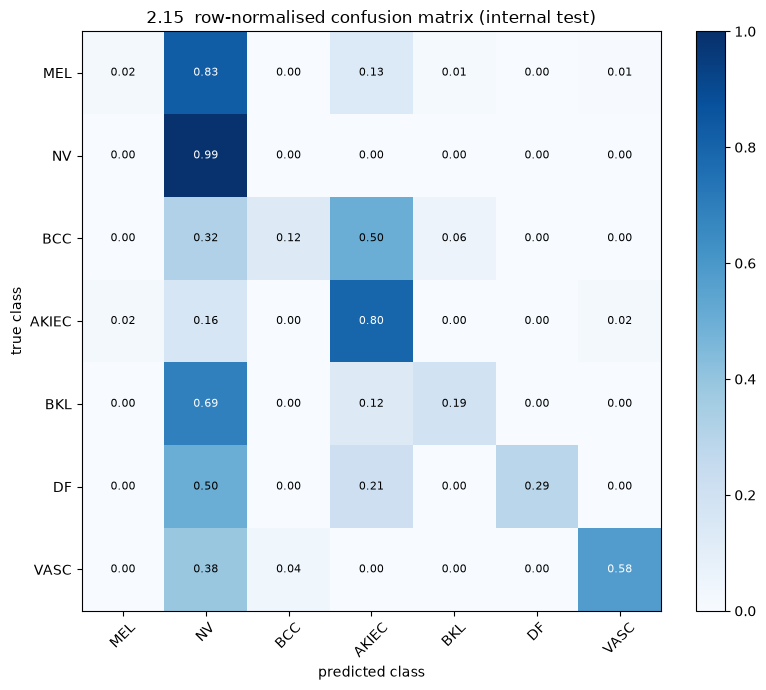

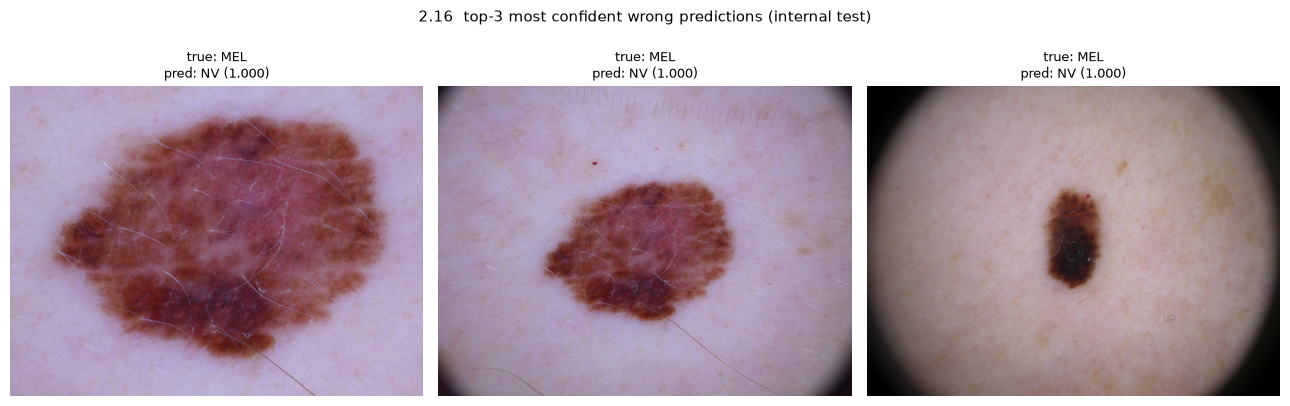

most confident errors: [('MEL', 'NV', 1.0), ('MEL', 'NV', 1.0), ('MEL', 'NV', 1.0)]
true predicted  count  row_fraction
 MEL        NV    129      0.826923
 BKL        NV    110      0.687500
 BCC     AKIEC     36      0.500000
 BCC        NV     23      0.319444
 MEL     AKIEC     21      0.134615
 BKL     AKIEC     20      0.125000


110

In [14]:
# 2.14 - Internal test evaluation with the selected weights.
model.load_weights(BEST_WEIGHTS)
test_loss, test_accuracy = evaluate(model, test_ds)
test_probs, test_labels = [], []
for images, labels in test_ds:
    test_probs.append(model(images, training=False).numpy())
    test_labels.append(np.argmax(labels.numpy(), axis=1))
test_probs = np.concatenate(test_probs)
test_labels = np.concatenate(test_labels)
test_pred = test_probs.argmax(axis=1)
test_macro_f1 = sklearn.metrics.f1_score(test_labels, test_pred, average="macro")
print(f"internal test loss: {test_loss:.4f} | accuracy: {test_accuracy:.4f} | macro F1: {test_macro_f1:.4f}")

classification_report = sklearn.metrics.classification_report(
    test_labels, test_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
(OUT_DIR / "tables" / "test_classification_report.txt").write_text(classification_report + "\n")
print(classification_report)

# 2.15 - Row-normalised confusion matrix (each row sums to 1).
confusion = sklearn.metrics.confusion_matrix(test_labels, test_pred, labels=np.arange(len(CLASS_NAMES)))
confusion_normalised = confusion / confusion.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
image_handle = ax.imshow(confusion_normalised, cmap="Blues", vmin=0, vmax=1)
for row in range(len(CLASS_NAMES)):
    for column in range(len(CLASS_NAMES)):
        value = confusion_normalised[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if value > 0.5 else "black")
ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=45)
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("2.15  row-normalised confusion matrix (internal test)")
fig.colorbar(image_handle, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 2.16 - The three most confident wrong predictions.
wrong_indices = np.where(test_pred != test_labels)[0]
confident_wrong = wrong_indices[np.argsort(test_probs[wrong_indices, test_pred[wrong_indices]])[::-1][:3]]
test_paths = isic2018[isic2018["split"] == "test"].reset_index(drop=True)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, index in zip(axes, confident_wrong):
    ax.imshow(Image.open(test_paths.loc[index, "path"]).convert("RGB"))
    ax.set_title(f"true: {CLASS_NAMES[test_labels[index]]}\n"
                 f"pred: {CLASS_NAMES[test_pred[index]]} ({test_probs[index, test_pred[index]]:.3f})", fontsize=9)
    ax.axis("off")
fig.suptitle("2.16  top-3 most confident wrong predictions (internal test)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "top_confident_errors.png", dpi=150, bbox_inches="tight")
plt.show()
print("most confident errors:", [
    (CLASS_NAMES[test_labels[index]], CLASS_NAMES[test_pred[index]],
     round(float(test_probs[index, test_pred[index]]), 3)) for index in confident_wrong])

# 2.17 - Error analysis evidence: most frequent confusion pairs.
confusion_pairs = [{"true": CLASS_NAMES[true_index], "predicted": CLASS_NAMES[predicted_index],
                    "count": int(confusion[true_index, predicted_index]),
                    "row_fraction": float(confusion_normalised[true_index, predicted_index])}
                   for true_index in range(len(CLASS_NAMES)) for predicted_index in range(len(CLASS_NAMES))
                   if true_index != predicted_index and confusion[true_index, predicted_index] > 0]
confusion_pairs = pd.DataFrame(confusion_pairs).sort_values("count", ascending=False)
confusion_pairs.to_csv(OUT_DIR / "tables" / "test_confusion_pairs.csv", index=False)
print(confusion_pairs.head(6).to_string(index=False))

test_metrics = {"test_loss": test_loss, "test_accuracy": float(test_accuracy), "macro_f1": float(test_macro_f1)}
(OUT_DIR / "tables" / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))


## 2.18–2.20 External dataset, unseen image and calibration

Required: external evaluation, unseen-image probabilities, softmax discussion, calibration. Produces: external table, bar chart, reliability diagram and ECE.

**Softmax and calibration.** The dense head outputs logits; softmax exponentiates them and normalises by their sum, so the seven outputs are positive and add to one. A classifier is calibrated when a predicted probability of 0.8 really is right about 80% of the time; the reliability diagram bins test predictions by confidence and compares mean confidence with empirical accuracy, and the expected calibration error (ECE) is the weighted average gap between the two.

**Results (real run).** On the 14,885-image ISIC 2019 external split the accuracy drops to **43.6%** (macro F1 0.175) and the loss rises to 3.24 - a clear domain shift. The model predicts NV for 12,605 of 14,885 images, so recall collapses for MEL (0.027), BCC (0.024) and DF (0.016) while NV recall stays at 0.966. Calibration on the internal test is also poor: **ECE = 0.189**, and the reliability diagram shows the top confidence bin (mean confidence 0.991) with only 83.4% empirical accuracy. Wrong predictions receive a mean confidence of 0.830 versus 0.968 for correct ones, and the most confident errors are confidently wrong (probability 1.000). The unseen-image example (ISIC_0000000) is predicted NV with P(malignant) = 0.00, i.e. the model inherits the class prior rather than the lesion evidence. These measurements are the evidence for the over-confidence and calibration discussion in section 2.20.


ISIC 2019 external (14885 images): loss 3.2392 | accuracy 0.4359 | macro F1 0.1748 | 455s
class  support  predicted   recall
  MEL     3409        103 0.026694
   NV     6170      12605 0.966126
  BCC     2809         83 0.024208
AKIEC      737        668 0.100407
  BKL     1525       1269 0.184262
   DF      124        137 0.016129
 VASC      111         20 0.099099


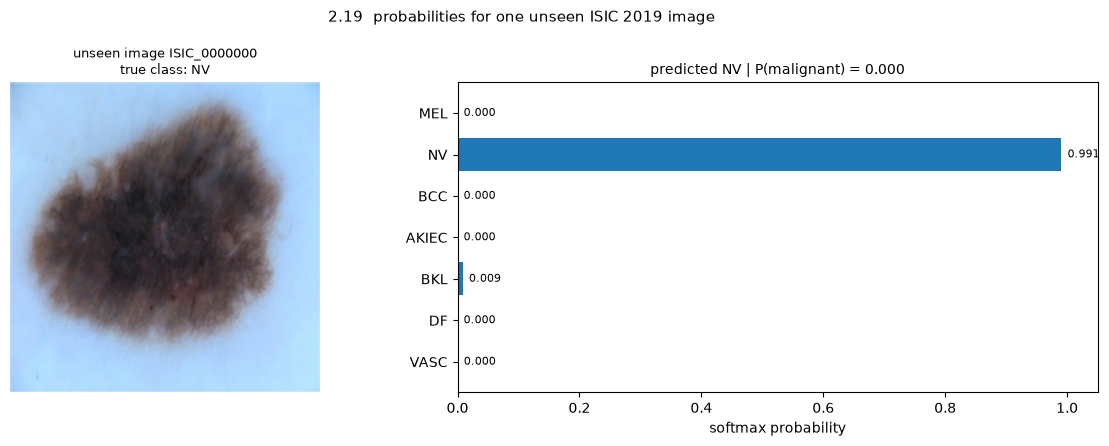

unseen image: ISIC_0000000 | true: NV | predicted: NV | P(malignant): 0.0


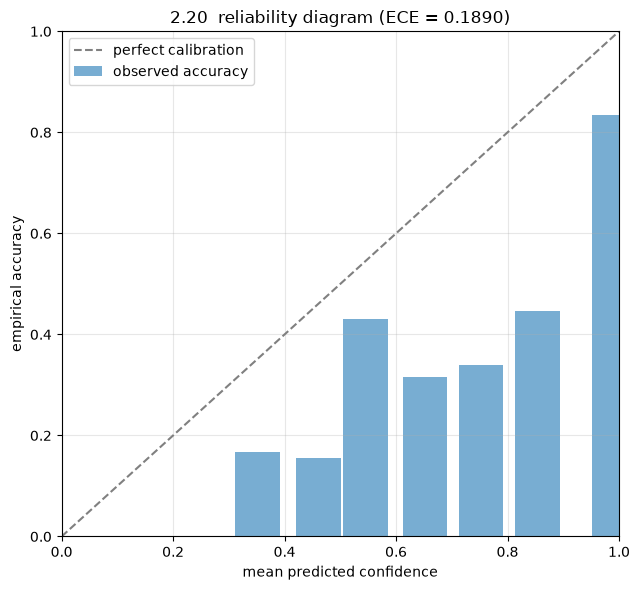

expected calibration error (internal test): 0.1890
mean confidence on wrong predictions: 0.8301 | mean confidence on correct predictions: 0.9676


119

In [15]:
# 2.18 - External evaluation on ISIC 2019 (7-class mapping, hash-deduplicated against ISIC 2018).
def external_dataset(dataframe, batch_size=32):
    paths = tf.constant(dataframe["path"].tolist())
    labels = tf.constant([CLASS_TO_INDEX[label] for label in dataframe["label"]], dtype=tf.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels)).map(
        lambda path, label: (tf.cast(decode_resize(path), tf.float32) / 255.0, tf.one_hot(label, len(CLASS_NAMES))),
        num_parallel_calls=AUTOTUNE)
    return dataset.batch(batch_size).prefetch(AUTOTUNE)

start = time.perf_counter()
external_probs, external_loss_sum, external_seen = [], 0.0, 0
for images, labels in external_dataset(isic2019):
    probabilities = model(images, training=False)
    external_probs.append(probabilities.numpy())
    external_loss_sum += float(tf.reduce_sum(sample_loss_fn(labels, probabilities)))
    external_seen += int(images.shape[0])
external_probs = np.concatenate(external_probs)
external_labels = np.array([CLASS_TO_INDEX[label] for label in isic2019["label"]])
external_pred = external_probs.argmax(axis=1)
external_loss = external_loss_sum / external_seen
external_accuracy = float((external_pred == external_labels).mean())
external_macro_f1 = float(sklearn.metrics.f1_score(external_labels, external_pred, average="macro"))
print(f"ISIC 2019 external ({external_seen} images): loss {external_loss:.4f} | accuracy {external_accuracy:.4f} | macro F1 {external_macro_f1:.4f} | {time.perf_counter() - start:.0f}s")

external_table = pd.DataFrame({
    "class": CLASS_NAMES,
    "support": [int((external_labels == index).sum()) for index in range(len(CLASS_NAMES))],
    "predicted": [int((external_pred == index).sum()) for index in range(len(CLASS_NAMES))],
    "recall": [float(((external_pred == index) & (external_labels == index)).sum() / max((external_labels == index).sum(), 1)) for index in range(len(CLASS_NAMES))],
})
external_table.to_csv(OUT_DIR / "tables" / "external_isic2019_per_class.csv", index=False)
print(external_table.to_string(index=False))

# 2.19 - One fixed unseen ISIC 2019 image: probabilities as a horizontal bar chart.
unseen_row = isic2019.iloc[0]
unseen_image = np.asarray(Image.open(unseen_row["path"]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
unseen_probs = model(tf.expand_dims(tf.convert_to_tensor(unseen_image), 0), training=False).numpy()[0]
malignant_probability = float(sum(unseen_probs[CLASS_TO_INDEX[label]] for label in ("MEL", "BCC", "AKIEC")))
fig, (image_axis, bar_axis) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
image_axis.imshow(unseen_image)
image_axis.set_title(f"unseen image {unseen_row['image']}\ntrue class: {unseen_row['label']}", fontsize=9)
image_axis.axis("off")
bar_axis.barh(CLASS_NAMES[::-1], unseen_probs[::-1], color="tab:blue")
for index, probability in enumerate(unseen_probs[::-1]):
    bar_axis.text(probability + 0.01, index, f"{probability:.3f}", va="center", fontsize=8)
bar_axis.set_xlim(0, 1.05)
bar_axis.set_xlabel("softmax probability")
bar_axis.set_title(f"predicted {CLASS_NAMES[int(unseen_probs.argmax())]} | P(malignant) = {malignant_probability:.3f}", fontsize=10)
fig.suptitle("2.19  probabilities for one unseen ISIC 2019 image", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "unseen_image_probabilities.png", dpi=150, bbox_inches="tight")
plt.show()
print("unseen image:", unseen_row["image"], "| true:", unseen_row["label"],
      "| predicted:", CLASS_NAMES[int(unseen_probs.argmax())], "| P(malignant):", round(malignant_probability, 3))

# 2.20 - Reliability diagram and expected calibration error on the internal test set.
def calibration_table(probabilities, labels, bins=10):
    confidence = probabilities.max(axis=1)
    correct = (probabilities.argmax(axis=1) == labels).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    rows = []
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.sum() == 0:
            continue
        rows.append({"bin_center": (lower + upper) / 2, "count": int(mask.sum()),
                     "mean_confidence": float(confidence[mask].mean()),
                     "accuracy": float(correct[mask].mean())})
    table = pd.DataFrame(rows)
    ece = float(np.sum(table["count"] / len(labels) * (table["accuracy"] - table["mean_confidence"]).abs()))
    return table, ece

reliability, ece = calibration_table(test_probs, test_labels)
reliability.to_csv(OUT_DIR / "tables" / "calibration_reliability.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.bar(reliability["mean_confidence"], reliability["accuracy"], width=0.08,
       color="tab:blue", alpha=0.6, label="observed accuracy")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("mean predicted confidence")
ax.set_ylabel("empirical accuracy")
ax.set_title(f"2.20  reliability diagram (ECE = {ece:.4f})")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "reliability_diagram.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"expected calibration error (internal test): {ece:.4f}")
print("mean confidence on wrong predictions: %.4f | mean confidence on correct predictions: %.4f" % (
    test_probs[test_labels != test_pred].max(axis=1).mean(),
    test_probs[test_labels == test_pred].max(axis=1).mean()))

external_metrics = {"images": int(external_seen), "loss": external_loss,
                    "accuracy": external_accuracy, "macro_f1": external_macro_f1}
(OUT_DIR / "tables" / "external_isic2019_metrics.json").write_text(json.dumps(external_metrics, indent=2))


## Artifacts, reproducibility and submission packaging

Required: one self-contained notebook and a verified results archive. Produces: weights, metrics JSON, all figures, results ZIP.

**Artifacts.** Everything the report needs is written with fixed names under `outputs/`: `figures/` (augmentation, feature maps, gradient magnitudes, training curves, confusion matrix, confident errors, unseen-image probabilities, reliability diagram), `tables/` (environment, split manifest, model summary, training history, classification report, metrics, calibration table) and `model/` (best and last weights). `outputs/Group_8_Results.zip` bundles figures + tables + weights so the results can be checked without rerunning training.


In [16]:
# Artifacts, reproducibility and submission packaging.
import zipfile

metrics = {
    "environment": ENV,
    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "stage_a_epochs": STAGE_A_EPOCHS,
    "stage_b_epochs": STAGE_B_EPOCHS,
    "head_lr": HEAD_LR,
    "finetune_lr": FINETUNE_LR,
    "internal_test": json.loads((OUT_DIR / "tables" / "test_metrics.json").read_text()),
    "external_isic2019": json.loads((OUT_DIR / "tables" / "external_isic2019_metrics.json").read_text()),
    "calibration_ece": ece,
    "splits": {name: int((isic2018["split"] == name).sum()) for name in ("train", "validation", "test")},
    "external_rows": int(len(isic2019)),
}
(OUT_DIR / "tables" / "metrics.json").write_text(json.dumps(metrics, indent=2))
archive_path = OUT_DIR / "Group_8_Results.zip"
if archive_path.is_file():
    archive_path.unlink()
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in ("figures", "tables"):
        for file_path in sorted((OUT_DIR / folder).rglob("*")):
            if file_path.is_file():
                archive.write(file_path, file_path.relative_to(OUT_DIR))
    archive.write(BEST_WEIGHTS, "model/best.weights.h5")      # selected model only
with zipfile.ZipFile(archive_path) as archive:
    names = archive.namelist()
print(f"results archive: {archive_path} ({archive_path.stat().st_size / 1024 / 1024:.1f} MB, {len(names)} files)")
print("\n".join(sorted(names)))


results archive: outputs/Group_8_Results.zip (86.2 MB, 22 files)
figures/augmentation_examples.png
figures/confusion_matrix.png
figures/feature_maps.png
figures/gradient_magnitudes_vgg_vs_resnet.png
figures/reliability_diagram.png
figures/top_confident_errors.png
figures/training_curves.png
figures/unseen_image_probabilities.png
model/best.weights.h5
tables/calibration_reliability.csv
tables/env.json
tables/external_isic2019_metrics.json
tables/external_isic2019_per_class.csv
tables/gradient_magnitudes_1_1.csv
tables/gradient_norms_2_2.csv
tables/isic2018_split.csv
tables/metrics.json
tables/model_summary.txt
tables/test_classification_report.txt
tables/test_confusion_pairs.csv
tables/test_metrics.json
tables/train_history.csv
